# ITRI626 — Phase 1: Data Preparation
### Pothole *severity* classification — build the patch dataset & leakage-safe split

This notebook turns the raw **Annotated Potholes with Severity Levels** dataset
(717 images + Pascal-VOC XML, 3 severity classes) into a clean, model-ready
**patch** dataset with a **leakage-safe train/val/test split**.

**What it does, in order**
1. Parse every XML annotation into a table of pothole objects.
2. Clean the boxes (clamp to image, drop degenerate/tiny boxes).
3. Exploratory analysis + a **box-size vs. severity** diagnostic (a key report figure).
4. Detect near-duplicate images with **perceptual hashing** (same pothole, different angle).
5. Split **at the image/duplicate-group level** (never per-patch) into 70/15/15, keeping
   the class balance — this is what prevents data leakage.
6. **Crop each pothole box → 224×224 patch**, saved into `train/val/test` class folders.
7. Write a `manifest.csv`, split files, and a `data_prep_summary.json` for the report.

Everything is seeded so the split is reproducible. Set `SEED` and paths in the config cell.


In [1]:
# --- Install dependencies (Colab/Kaggle) -------------------------------------
# imagehash is the only non-standard package; the rest ship with Colab/Kaggle.
import importlib, subprocess, sys
for pkg in ["imagehash", "pillow", "pandas", "matplotlib", "scikit-learn"]:
    name = {"pillow":"PIL", "scikit-learn":"sklearn"}.get(pkg, pkg)
    try:
        importlib.import_module(name)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
print("dependencies ready")

dependencies ready


In [2]:
# --- Configuration -----------------------------------------------------------
from pathlib import Path

SEED        = 42          # reproducible split — report this number
IMG_SIZE    = 224         # patch size fed to the models
PAD_FRAC    = 0.10        # context margin around each box (fraction of box size)
MIN_BOX_PX  = 16          # drop boxes smaller than this on either side (noise)
PHASH_SIZE  = 16          # perceptual-hash resolution
PHASH_MAXHAMMING = 8      # <= this Hamming distance => treated as near-duplicate
SPLIT_FRACS = (0.70, 0.15, 0.15)   # train / val / test

# --- Auto-find the dataset (searches for a folder with images/ + annotations/) --
def find_data_dir():
    roots = ["/kaggle/input", "/content", ".",
             str(Path.home() / "Desktop/PotholeClassifier")]
    for root in roots:
        rp = Path(root)
        if not rp.exists():
            continue
        candidates = [rp] + [p for p in rp.rglob("*") if p.is_dir()]
        for p in candidates:
            try:
                if (p / "images").is_dir() and (p / "annotations").is_dir():
                    return p
            except PermissionError:
                continue
    return None

DATA_DIR = find_data_dir()
if DATA_DIR is None:
    # Show what IS in /kaggle/input so we can see the real path
    for r in ["/kaggle/input", "/content", "."]:
        rp = Path(r)
        if rp.exists():
            print(f"Contents of {r}:")
            for x in sorted(rp.rglob("*"))[:40]:
                print("   ", x)
    raise FileNotFoundError(
        "Couldn't locate images/ + annotations/. Look at the listing above and "
        "set DATA_DIR = Path('/kaggle/input/.../<folder with images and annotations>')")

IMAGES_DIR = DATA_DIR / "images"
ANNOTS_DIR = DATA_DIR / "annotations"
OUT_DIR    = Path("/kaggle/working/patches_dataset") if Path("/kaggle/working").exists() \
             else Path("patches_dataset")
print("DATA_DIR :", DATA_DIR)
print("OUT_DIR  :", OUT_DIR)

DATA_DIR : /kaggle/input/datasets/idanbaru/annotated-potholes-with-severity-levels
OUT_DIR  : /kaggle/working/patches_dataset


In [3]:
# --- Reproducibility ---------------------------------------------------------
import random, numpy as np
random.seed(SEED); np.random.seed(SEED)

## 1. Parse annotations

In [4]:
import xml.etree.ElementTree as ET
import pandas as pd

CLASSES = ["minor_pothole", "medium_pothole", "major_pothole"]

def parse_annotations(annots_dir, images_dir):
    rows, skipped = [], []
    for xml in sorted(annots_dir.glob("*.xml")):
        root = ET.parse(xml).getroot()
        fname = root.findtext("filename") or (xml.stem + ".jpg")
        img_path = images_dir / fname
        W = int(root.findtext("size/width"));  H = int(root.findtext("size/height"))
        for i, o in enumerate(root.findall("object")):
            name = o.findtext("name")
            b = o.find("bndbox")
            xmin, ymin, xmax, ymax = (int(float(b.findtext(k))) for k in ("xmin","ymin","xmax","ymax"))
            rows.append(dict(source_image=fname, img_path=str(img_path), obj_idx=i,
                             cls=name, W=W, H=H,
                             xmin=xmin, ymin=ymin, xmax=xmax, ymax=ymax))
    return pd.DataFrame(rows)

df_raw = parse_annotations(ANNOTS_DIR, IMAGES_DIR)
print(f"Parsed {df_raw['source_image'].nunique()} images, {len(df_raw)} pothole objects")
print("\nRaw class counts:")
print(df_raw['cls'].value_counts())

Parsed 716 images, 1887 pothole objects

Raw class counts:
cls
medium_pothole    869
major_pothole     600
minor_pothole     418
Name: count, dtype: int64


## 2. Clean boxes

In [5]:
def clean_boxes(df):
    d = df.copy()
    # clamp to image bounds
    d["xmin"] = d[["xmin","W"]].min(axis=1).clip(lower=0)
    d["ymin"] = d[["ymin","H"]].min(axis=1).clip(lower=0)
    d["xmax"] = d[["xmax","W"]].min(axis=1)
    d["ymax"] = d[["ymax","H"]].min(axis=1)
    d["bw"] = d["xmax"] - d["xmin"]
    d["bh"] = d["ymax"] - d["ymin"]
    before = len(d)
    # drop unknown classes, degenerate and tiny boxes
    d = d[d["cls"].isin(CLASSES)]
    d = d[(d["bw"] >= MIN_BOX_PX) & (d["bh"] >= MIN_BOX_PX)]
    d["area"]     = d["bw"] * d["bh"]
    d["area_pct"] = d["area"] / (d["W"] * d["H"]) * 100
    print(f"Dropped {before - len(d)} boxes (unknown class / degenerate / < {MIN_BOX_PX}px). "
          f"Kept {len(d)}.")
    return d.reset_index(drop=True)

df = clean_boxes(df_raw)
print("\nClass counts after cleaning:")
print(df['cls'].value_counts())

Dropped 345 boxes (unknown class / degenerate / < 16px). Kept 1542.

Class counts after cleaning:
cls
medium_pothole    672
major_pothole     529
minor_pothole     341
Name: count, dtype: int64


## 3. Exploratory analysis + box-size vs. severity diagnostic
This is the honesty figure for the report: it shows severity **tracks** box size but is **not** determined by it, so the models have real appearance signal to learn.

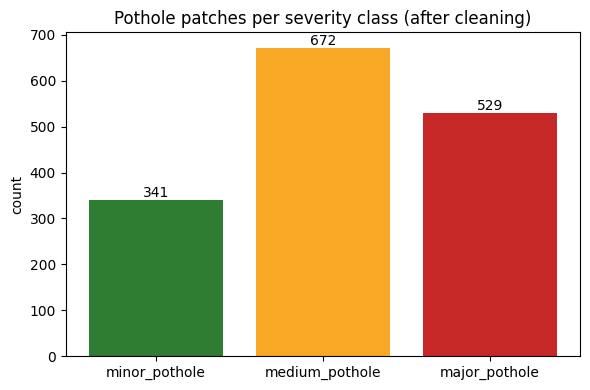

In [6]:
import matplotlib.pyplot as plt
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = OUT_DIR / "figures"; FIG_DIR.mkdir(exist_ok=True)
COLORS = {"minor_pothole":"#2e7d32", "medium_pothole":"#f9a825", "major_pothole":"#c62828"}

# (a) class distribution
fig, ax = plt.subplots(figsize=(6,4))
counts = df['cls'].value_counts().reindex(CLASSES)
ax.bar(CLASSES, counts.values, color=[COLORS[c] for c in CLASSES])
ax.set_title("Pothole patches per severity class (after cleaning)")
ax.set_ylabel("count")
for i,v in enumerate(counts.values): ax.text(i, v, str(v), ha="center", va="bottom")
plt.tight_layout(); plt.savefig(FIG_DIR/"class_distribution.png", dpi=120); plt.show()

/tmp/ipykernel_16/1646850245.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[c.replace("_pothole","") for c in CLASSES],


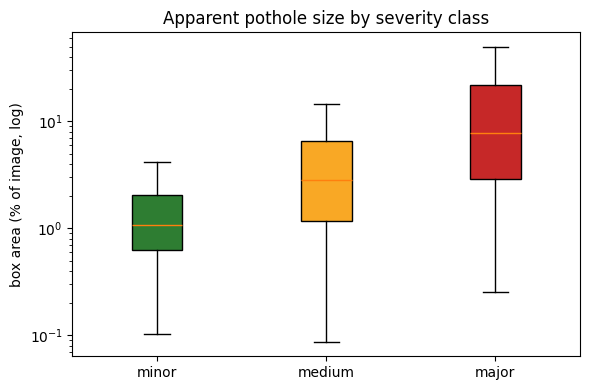

minor_pothole    n= 341  mean=  1.79%  median=  1.09%
medium_pothole   n= 672  mean=  5.15%  median=  2.85%
major_pothole    n= 529  mean= 14.82%  median=  7.82%


In [7]:
# (b) box area (% of image) by severity — boxplot on log scale
fig, ax = plt.subplots(figsize=(6,4))
data = [df[df.cls==c]["area_pct"].values for c in CLASSES]
bp = ax.boxplot(data, labels=[c.replace("_pothole","") for c in CLASSES],
                patch_artist=True, showfliers=False)
for patch,c in zip(bp['boxes'], CLASSES): patch.set_facecolor(COLORS[c])
ax.set_yscale("log"); ax.set_ylabel("box area (% of image, log)")
ax.set_title("Apparent pothole size by severity class")
plt.tight_layout(); plt.savefig(FIG_DIR/"size_vs_severity.png", dpi=120); plt.show()

for c in CLASSES:
    v = df[df.cls==c]["area_pct"]
    print(f"{c:16s} n={len(v):4d}  mean={v.mean():6.2f}%  median={v.median():6.2f}%")

In [8]:
# (c) Can size ALONE recover severity? Best 2-threshold rule vs majority baseline.
from itertools import combinations
vals = df["area_pct"].values; labs = df["cls"].values
rank = {"minor_pothole":0,"medium_pothole":1,"major_pothole":2}

def size_rule_acc(t1, t2):
    pred = np.where(vals < t1, "minor_pothole",
            np.where(vals < t2, "medium_pothole", "major_pothole"))
    return (pred == labs).mean()

cand = np.quantile(vals, np.linspace(0.02, 0.98, 60))
best_acc, best_t = 0, (None,None)
for t1, t2 in combinations(sorted(set(np.round(cand,3))), 2):
    a = size_rule_acc(t1, t2)
    if a > best_acc: best_acc, best_t = a, (t1,t2)

majority = pd.Series(labs).value_counts(normalize=True).max()
# Spearman correlation of area vs severity rank
from scipy.stats import spearmanr
rho, _ = spearmanr(vals, [rank[l] for l in labs])
print(f"Best size-ONLY classifier : {best_acc*100:5.1f}%  (thresholds {best_t})")
print(f"Majority-class baseline    : {majority*100:5.1f}%")
print(f"Spearman(area, severity)   : {rho:.3f}")
print("\nReading: size explains a lot but is far from the whole label -> appearance signal is real,")
print("and cropping+resizing (next steps) removes absolute size so models must use appearance.")

Best size-ONLY classifier :  55.8%  (thresholds (np.float64(0.617), np.float64(10.25)))
Majority-class baseline    :  43.6%
Spearman(area, severity)   : 0.508

Reading: size explains a lot but is far from the whole label -> appearance signal is real,
and cropping+resizing (next steps) removes absolute size so models must use appearance.


## 4. Near-duplicate detection (leakage prevention, part 1)
The dataset README warns that the *same pothole* appears in multiple images from different angles. We hash every image and union near-duplicates into **groups**; the split in step 5 keeps each group entirely inside one split.

In [9]:
import imagehash
from PIL import Image

unique_imgs = df[["source_image","img_path"]].drop_duplicates().reset_index(drop=True)

def phash_of(path):
    try:
        return imagehash.phash(Image.open(path).convert("RGB"), hash_size=PHASH_SIZE)
    except Exception as e:
        print("hash failed:", path, e); return None

unique_imgs["phash"] = unique_imgs["img_path"].map(phash_of)
unique_imgs = unique_imgs[unique_imgs["phash"].notna()].reset_index(drop=True)

# Union-Find over images whose hashes are within PHASH_MAXHAMMING
parent = list(range(len(unique_imgs)))
def find(x):
    while parent[x]!=x: parent[x]=parent[parent[x]]; x=parent[x]
    return x
def union(a,b):
    ra,rb=find(a),find(b)
    if ra!=rb: parent[ra]=rb

hashes = unique_imgs["phash"].tolist()
for i in range(len(hashes)):
    for j in range(i+1, len(hashes)):
        if (hashes[i]-hashes[j]) <= PHASH_MAXHAMMING:
            union(i,j)

unique_imgs["group"] = [find(i) for i in range(len(unique_imgs))]
# renumber groups 0..k-1
remap = {g:k for k,g in enumerate(sorted(unique_imgs["group"].unique()))}
unique_imgs["group"] = unique_imgs["group"].map(remap)

n_groups = unique_imgs["group"].nunique()
gsizes = unique_imgs["group"].value_counts()
print(f"{len(unique_imgs)} images -> {n_groups} duplicate-groups")
print(f"Images in a multi-image group: {(gsizes[gsizes>1].sum())}  "
      f"(largest group = {gsizes.max()} images)")
df = df.merge(unique_imgs[["source_image","group"]], on="source_image", how="left")

hash failed: /kaggle/input/datasets/idanbaru/annotated-potholes-with-severity-levels/images/0b360769-img-338.jpg [Errno 2] No such file or directory: '/kaggle/input/datasets/idanbaru/annotated-potholes-with-severity-levels/images/0b360769-img-338.jpg'
hash failed: /kaggle/input/datasets/idanbaru/annotated-potholes-with-severity-levels/images/96d6e1f7-img-339.jpg [Errno 2] No such file or directory: '/kaggle/input/datasets/idanbaru/annotated-potholes-with-severity-levels/images/96d6e1f7-img-339.jpg'
hash failed: /kaggle/input/datasets/idanbaru/annotated-potholes-with-severity-levels/images/7f54daf5-img-349.jpg [Errno 2] No such file or directory: '/kaggle/input/datasets/idanbaru/annotated-potholes-with-severity-levels/images/7f54daf5-img-349.jpg'
hash failed: /kaggle/input/datasets/idanbaru/annotated-potholes-with-severity-levels/images/27592eb4-img-389.jpg [Errno 2] No such file or directory: '/kaggle/input/datasets/idanbaru/annotated-potholes-with-severity-levels/images/27592eb4-img-3

## 5. Leakage-safe, class-balanced split (70/15/15)
We assign whole duplicate-groups to splits with a seeded greedy rule that keeps each class's proportion close to the target. No image (or its near-duplicates) can appear in more than one split.

In [10]:
# Build per-group class-count vectors
grp = (df.groupby(["group","cls"]).size().unstack(fill_value=0)
         .reindex(columns=CLASSES, fill_value=0))
group_ids = grp.index.tolist()

# Targets = fraction of each class total
totals = grp.sum(axis=0)
targets = {s: totals * f for s, f in zip(["train","val","test"], SPLIT_FRACS)}
current = {s: pd.Series(0, index=CLASSES, dtype=float) for s in ["train","val","test"]}
assignment = {}

# Assign larger/rarer-heavy groups first; shuffle for reproducible tie-breaks
rng = np.random.default_rng(SEED)
order = sorted(group_ids, key=lambda g: grp.loc[g].sum(), reverse=True)
# light shuffle within equal sizes
order = list(rng.permutation(order)) if False else order

for g in order:
    vec = grp.loc[g].astype(float)
    # score each split by remaining need for this group's classes (higher = more room)
    scores = {}
    for s in ["train","val","test"]:
        deficit = (targets[s] - current[s]).clip(lower=0)
        denom = vec.sum() if vec.sum() else 1
        scores[s] = float((deficit * vec).sum() / denom)
    s = max(scores, key=scores.get)
    assignment[g] = s
    current[s] += vec

split_of_group = assignment
df["split"] = df["group"].map(split_of_group)

# Report per-split class distribution
dist = (df.groupby(["split","cls"]).size().unstack(fill_value=0)
          .reindex(index=["train","val","test"], columns=CLASSES, fill_value=0))
print("Patches per split x class:\n")
print(dist)
print("\nPer-split share of each class:")
print((dist / dist.sum(axis=0) * 100).round(1))

Patches per split x class:

cls    minor_pothole  medium_pothole  major_pothole
split                                              
train            232             456            347
val               50              98             75
test              49              98             74

Per-split share of each class:
cls    minor_pothole  medium_pothole  major_pothole
split                                              
train           70.1            69.9           70.0
val             15.1            15.0           15.1
test            14.8            15.0           14.9


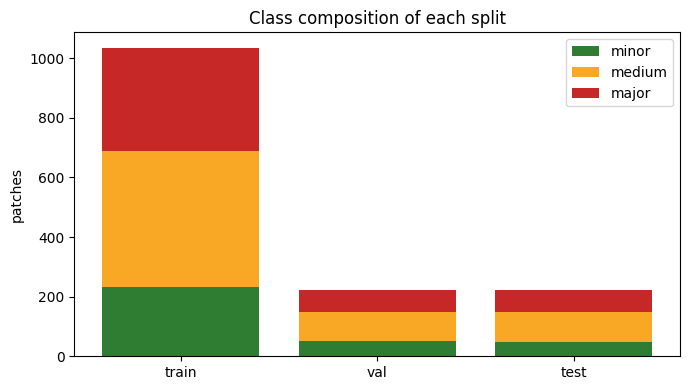

In [11]:
# Visualise the split balance
fig, ax = plt.subplots(figsize=(7,4))
bottom = np.zeros(3)
xs = ["train","val","test"]
for c in CLASSES:
    vals_ = dist[c].reindex(xs).values
    ax.bar(xs, vals_, bottom=bottom, label=c.replace("_pothole",""), color=COLORS[c])
    bottom += vals_
ax.set_title("Class composition of each split"); ax.set_ylabel("patches"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR/"split_composition.png", dpi=120); plt.show()

## 6. Crop patches → 224×224 and save into class folders
Layout is `patches_dataset/<split>/<class>/*.jpg` so it loads directly with `torchvision.datasets.ImageFolder` (or `keras.utils.image_dataset_from_directory`).

In [12]:
from PIL import Image

def crop_patch(img, box, pad_frac, size):
    xmin, ymin, xmax, ymax = box
    bw, bh = xmax-xmin, ymax-ymin
    px, py = int(bw*pad_frac), int(bh*pad_frac)
    L = max(0, xmin-px); T = max(0, ymin-py)
    R = min(img.width, xmax+px); B = min(img.height, ymax+py)
    return img.crop((L,T,R,B)).resize((size,size), Image.BILINEAR)

# fresh output dirs
import shutil
for s in ["train","val","test"]:
    for c in CLASSES:
        (OUT_DIR/s/c).mkdir(parents=True, exist_ok=True)

records, n_ok, n_fail = [], 0, 0
img_cache = {}
for row in df.itertuples(index=False):
    try:
        if row.img_path not in img_cache:
            img_cache[row.img_path] = Image.open(row.img_path).convert("RGB")
        img = img_cache[row.img_path]
        patch = crop_patch(img, (row.xmin,row.ymin,row.xmax,row.ymax), PAD_FRAC, IMG_SIZE)
        stem = Path(row.source_image).stem
        pname = f"{stem}_obj{row.obj_idx}_{row.cls}.jpg"
        rel = f"{row.split}/{row.cls}/{pname}"
        patch.save(OUT_DIR/rel, quality=92)
        records.append(dict(patch=rel, source_image=row.source_image, group=int(row.group),
                            cls=row.cls, split=row.split, area_pct=round(row.area_pct,4),
                            xmin=row.xmin, ymin=row.ymin, xmax=row.xmax, ymax=row.ymax))
        n_ok += 1
    except Exception as e:
        n_fail += 1
        if n_fail <= 5: print("crop failed:", row.source_image, e)
print(f"Saved {n_ok} patches ({n_fail} failed).")

crop failed: 0b360769-img-338.jpg [Errno 2] No such file or directory: '/kaggle/input/datasets/idanbaru/annotated-potholes-with-severity-levels/images/0b360769-img-338.jpg'
crop failed: 96d6e1f7-img-339.jpg [Errno 2] No such file or directory: '/kaggle/input/datasets/idanbaru/annotated-potholes-with-severity-levels/images/96d6e1f7-img-339.jpg'
crop failed: 96d6e1f7-img-339.jpg [Errno 2] No such file or directory: '/kaggle/input/datasets/idanbaru/annotated-potholes-with-severity-levels/images/96d6e1f7-img-339.jpg'
crop failed: 96d6e1f7-img-339.jpg [Errno 2] No such file or directory: '/kaggle/input/datasets/idanbaru/annotated-potholes-with-severity-levels/images/96d6e1f7-img-339.jpg'
crop failed: 96d6e1f7-img-339.jpg [Errno 2] No such file or directory: '/kaggle/input/datasets/idanbaru/annotated-potholes-with-severity-levels/images/96d6e1f7-img-339.jpg'
Saved 1479 patches (63 failed).


## 7. Write manifest, split files, and summary

In [13]:
import json
manifest = pd.DataFrame(records)
manifest.to_csv(OUT_DIR/"manifest.csv", index=False)

# split files: which SOURCE images fall in each split (for reproducibility)
for s in ["train","val","test"]:
    imgs = sorted(df[df.split==s]["source_image"].unique())
    (OUT_DIR/f"split_{s}.txt").write_text("\n".join(imgs))

summary = dict(
    seed=SEED, img_size=IMG_SIZE, pad_frac=PAD_FRAC, min_box_px=MIN_BOX_PX,
    phash_size=PHASH_SIZE, phash_maxhamming=PHASH_MAXHAMMING, split_fracs=SPLIT_FRACS,
    n_source_images=int(df["source_image"].nunique()),
    n_duplicate_groups=int(df["group"].nunique()),
    n_patches=int(len(manifest)),
    class_counts={c:int((manifest.cls==c).sum()) for c in CLASSES},
    per_split={s:{c:int(((manifest.split==s)&(manifest.cls==c)).sum()) for c in CLASSES}
               for s in ["train","val","test"]},
    dataset_source="Kaggle: idanbaru/annotated-potholes-with-severity-levels",
)
(OUT_DIR/"data_prep_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "seed": 42,
  "img_size": 224,
  "pad_frac": 0.1,
  "min_box_px": 16,
  "phash_size": 16,
  "phash_maxhamming": 8,
  "split_fracs": [
    0.7,
    0.15,
    0.15
  ],
  "n_source_images": 713,
  "n_duplicate_groups": 697,
  "n_patches": 1479,
  "class_counts": {
    "minor_pothole": 331,
    "medium_pothole": 652,
    "major_pothole": 496
  },
  "per_split": {
    "train": {
      "minor_pothole": 232,
      "medium_pothole": 456,
      "major_pothole": 347
    },
    "val": {
      "minor_pothole": 50,
      "medium_pothole": 98,
      "major_pothole": 75
    },
    "test": {
      "minor_pothole": 49,
      "medium_pothole": 98,
      "major_pothole": 74
    }
  },
  "dataset_source": "Kaggle: idanbaru/annotated-potholes-with-severity-levels"
}


## 8. Sample patches per class (sanity check)

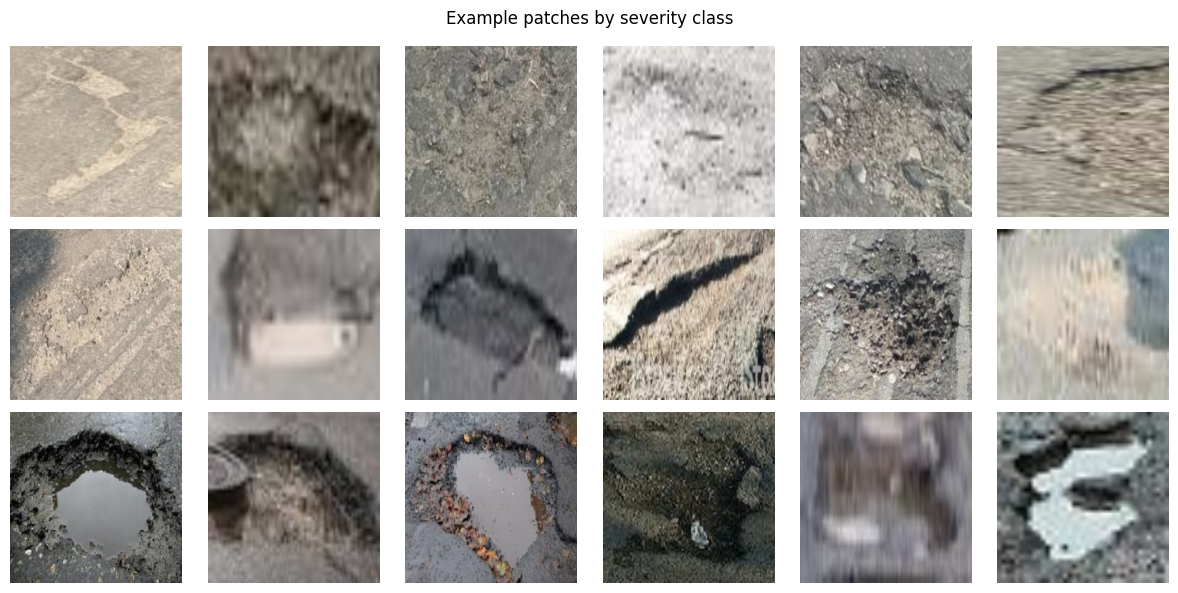

In [14]:
fig, axes = plt.subplots(len(CLASSES), 6, figsize=(12, 6))
for r,c in enumerate(CLASSES):
    sub = manifest[manifest.cls==c].sample(min(6,len(manifest[manifest.cls==c])),
                                           random_state=SEED)
    for a,(_,rec) in zip(axes[r], sub.iterrows()):
        a.imshow(Image.open(OUT_DIR/rec["patch"])); a.axis("off")
    axes[r][0].set_ylabel(c.replace("_pothole",""), rotation=0, ha="right", va="center")
    for a in axes[r][len(sub):]: a.axis("off")
plt.suptitle("Example patches by severity class"); plt.tight_layout()
plt.savefig(FIG_DIR/"sample_patches.png", dpi=120); plt.show()

## Done — Phase 1 outputs

In `patches_dataset/`:
- `train/ val/ test/` with `<class>/*.jpg` patches (ready for `ImageFolder`)
- `manifest.csv` — every patch with its source image, group, class, split, box, size
- `split_train.txt / split_val.txt / split_test.txt` — source-image split lists
- `data_prep_summary.json` — all the numbers + settings for the report
- `figures/` — class distribution, size-vs-severity, split composition, sample patches

**Next (Phase 2/3):** point the model notebooks at `patches_dataset/` and train the
custom CNN, EfficientNetV2-S, and ViT-B/16 on this exact split.
